# 08 — `scikit-learn` (Probabilitas dalam Machine Learning)
**Mata Kuliah:** Probabilitas dan Statistika | **Nama / NIM:** ________

scikit-learn memperlihatkan probabilitas **bekerja di dalam algoritma**: Naive Bayes (Teorema Bayes), Gaussian Mixture & KDE (estimasi distribusi), serta metrik probabilistik (log-loss, Brier, kalibrasi, mutual information).

## 1. Eksplorasi Library
| Modul / kelas | Kegunaan |
|---|---|
| `naive_bayes.GaussianNB / MultinomialNB / BernoulliNB` | Klasifikasi Bayes dengan asumsi independensi fitur; `predict_proba` |
| `feature_extraction.text.CountVectorizer` | Teks → hitungan kata (fitur multinomial) |
| `mixture.GaussianMixture` | Estimasi campuran Normal (EM), `predict_proba` = posterior komponen, `bic` |
| `neighbors.KernelDensity` | Estimasi PDF nonparametrik |
| `linear_model.LogisticRegression` | P(y\|x) diskriminatif |
| `metrics`: `confusion_matrix`, `roc_auc_score`, `log_loss`, `brier_score_loss`, `mutual_info_score` | Evaluasi probabilistik |
| `calibration.calibration_curve` | Apakah probabilitas model dapat dipercaya? |
| `utils.resample`, `model_selection.cross_val_score` | Bootstrap & validasi silang |

In [1]:
import numpy as np, pandas as pd, math, matplotlib.pyplot as plt
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import KernelDensity
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, roc_auc_score, log_loss, brier_score_loss, mutual_info_score
from sklearn.calibration import calibration_curve
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.datasets import load_iris
from scipy import stats
import sklearn; print("scikit-learn", sklearn.__version__)
rng=np.random.default_rng(11)

scikit-learn 1.9.1


## 2. Implementasi pada Permasalahan Probabilitas
### Soal 2.1 — Filter spam: Naive Bayes manual vs `MultinomialNB`
Korpus kecil (6 spam, 6 bukan spam). Hitung manual P(spam|pesan) dengan *Laplace smoothing* (α=1) dan bandingkan dengan `predict_proba`.
**Rumus:** P(spam|w₁..wₙ) ∝ P(spam)·∏P(wᵢ|spam), P(w|c)=(count(w,c)+1)/(total_c+|V|).

In [2]:
spam=["menang hadiah gratis sekarang","klik link gratis hadiah","diskon besar gratis klik","hadiah uang tunai menang","gratis pulsa klik sekarang","menang undian hadiah besar"]
ham =["jadwal rapat besok pagi","tolong kirim laporan tugas","tugas probabilitas dikumpulkan besok","rapat proyek jam sepuluh","kirim jadwal kuliah besok","laporan praktikum sudah selesai"]
X_txt=spam+ham; y=np.array([1]*6+[0]*6)
cv=CountVectorizer(); X=cv.fit_transform(X_txt); V=X.shape[1]
nb=MultinomialNB(alpha=1.0).fit(X,y)

msg=["gratis hadiah besok"]; xm=cv.transform(msg)
print("kosakata:",V,"| pesan uji:",msg)
# --- manual
counts=np.array([X[y==c].sum(0).A1 for c in (0,1)])
logp=[]
for c in (0,1):
    lik=(counts[c]+1)/(counts[c].sum()+V)
    logp.append(math.log(.5)+ (xm.toarray()[0]*np.log(lik)).sum())
post_manual=np.exp(logp)/np.exp(logp).sum()
print("manual  P(ham),P(spam):",post_manual.round(4))
print("sklearn P(ham),P(spam):",nb.predict_proba(xm)[0].round(4))
vocab=np.array(cv.get_feature_names_out()); top=np.argsort(nb.feature_log_prob_[1]-nb.feature_log_prob_[0])[::-1][:5]
print("kata paling 'spammy':",vocab[top].tolist())

kosakata: 29 | pesan uji: ['gratis hadiah besok']
manual  P(ham),P(spam): [0.1379 0.8621]
sklearn P(ham),P(spam): [0.1379 0.8621]
kata paling 'spammy': ['hadiah', 'gratis', 'menang', 'klik', 'sekarang']


**Interpretasi:** Perhitungan manual (Bayes + independensi kata + Laplace) identik dengan `MultinomialNB.predict_proba`. Pesan "gratis hadiah besok" condong spam karena dua kata spammy meski "besok" khas bukan-spam. Smoothing mencegah probabilitas nol untuk kata yang tak pernah muncul di salah satu kelas.

### Soal 2.2 — Matriks konfusi sebagai peluang bersyarat & efek *base rate*
Deteksi intrusi: simulasikan lalu-lintas dengan prevalensi serangan 1% vs 30%, lakukan klasifikasi `GaussianNB`, hitung sensitivitas, spesifisitas, dan **presisi = P(serangan|alarm)** (Bayes).

In [3]:
def gen(n,prev,seed):
    r=np.random.default_rng(seed); yy=(r.random(n)<prev).astype(int)
    return np.where(yy[:,None]==1,r.normal(2,1,(n,2)),r.normal(0,1,(n,2))),yy
# satu model dilatih pada data seimbang (prior 0.5), lalu diuji pada prevalensi berbeda
Xtr,ytr=gen(40_000,.5,0); m=GaussianNB().fit(Xtr,ytr)
rows=[]
for prev in (.01,.10,.30,.50):
    Xte,yte=gen(400_000,prev,5); pred=m.predict(Xte)
    tn,fp,fn,tp=confusion_matrix(yte,pred).ravel()
    sens=tp/(tp+fn); spec=tn/(tn+fp); ppv=tp/(tp+fp)
    rows.append(dict(prevalensi=prev,sens=round(sens,3),spec=round(spec,3),presisi=round(ppv,3),
                     presisi_Bayes=round(sens*prev/(sens*prev+(1-spec)*(1-prev)),3),AUC=round(roc_auc_score(yte,m.predict_proba(Xte)[:,1]),3)))
print(pd.DataFrame(rows))

   prevalensi   sens   spec  presisi  presisi_Bayes    AUC
0        0.01  0.918  0.923    0.109          0.108  0.977
1        0.10  0.921  0.923    0.571          0.571  0.978
2        0.30  0.920  0.924    0.837          0.837  0.977
3        0.50  0.919  0.924    0.923          0.923  0.977


**Interpretasi:** Model **yang sama** (sensitivitas ≈0,92; spesifisitas ≈0,92; AUC ≈0,98 — konstan) memberi presisi yang sangat berbeda menurut prevalensi: ±11% pada prevalensi 1%, 57% pada 10%, 84% pada 30%, dan 92% pada 50%. Kolom `presisi_Bayes` (dihitung dari sens, spes, prevalensi saja) cocok dengan presisi empiris → presisi adalah probabilitas posterior P(serangan|alarm). Akurasi/AUC tidak cukup; selalu laporkan prevalensi.

### Soal 2.3 — Kualitas probabilitas: log-loss, Brier, dan kalibrasi
Bandingkan `GaussianNB` dan `LogisticRegression` pada data yang fiturnya **berkorelasi** (melanggar asumsi independensi Naive Bayes).

               AUC  logloss   brier  p_ekstrem
GaussianNB  0.7144    0.656  0.2253     0.0684
LogReg      0.7144    0.618  0.2149     0.0004


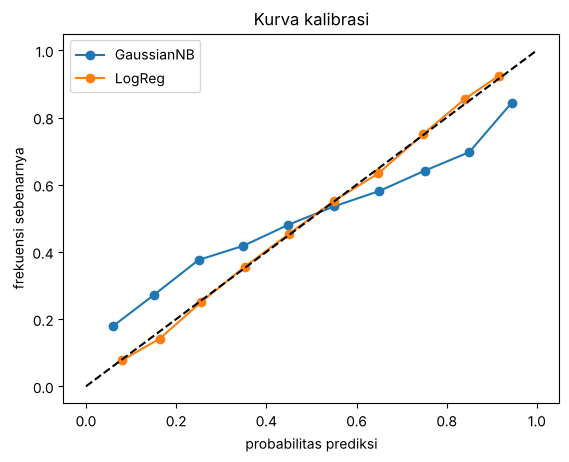

In [4]:
n=20_000; yy=(rng.random(n)<.5).astype(int)
cov=[[1,.9],[.9,1]]
Xf=np.array([rng.multivariate_normal([m,m],cov) for m in np.where(yy==1,.8,0)])
Xtr,Xte,ytr,yte=train_test_split(Xf,yy,test_size=.5,random_state=1)
res={}
for nm,m in {"GaussianNB":GaussianNB(),"LogReg":LogisticRegression()}.items():
    p=m.fit(Xtr,ytr).predict_proba(Xte)[:,1]
    res[nm]=dict(AUC=roc_auc_score(yte,p),logloss=log_loss(yte,p),brier=brier_score_loss(yte,p),p_ekstrem=((p<.05)|(p>.95)).mean())
    fp,mp=calibration_curve(yte,p,n_bins=10); plt.plot(mp,fp,'o-',label=nm)
print(pd.DataFrame(res).T.round(4))
plt.plot([0,1],[0,1],'k--'); plt.xlabel("probabilitas prediksi"); plt.ylabel("frekuensi sebenarnya"); plt.legend(); plt.title("Kurva kalibrasi"); plt.show()

**Interpretasi:** Naive Bayes menganggap fitur independen padahal korelasi 0,9, sehingga bukti terhitung ganda → probabilitas **terlalu ekstrem** (±6,8% prediksinya <0,05 atau >0,95 vs 0,04% pada LogReg; log-loss 0,656 vs 0,618; Brier 0,225 vs 0,215). Logistic regression lebih terkalibrasi. NB masih baik untuk *ranking* (AUC mirip) tetapi bukan untuk membaca angka peluang.

### Soal 2.4 — Mutual information & independensi
Ukur ketergantungan antar variabel kategorik: (a) independen, (b) bergantung kuat, (c) XOR. Mutual information I(X;Y) = 0 ⇔ independen.

In [5]:
n=50_000
a=rng.integers(0,2,n); b_ind=rng.integers(0,2,n); b_dep=np.where(rng.random(n)<.9,a,1-a)
print("I(X;Y) independen  =",round(mutual_info_score(a,b_ind),5),"nat")
print("I(X;Y) bergantung  =",round(mutual_info_score(a,b_dep),4),"nat | teori =",round(math.log(2)-(-.9*math.log(.9)-.1*math.log(.1)),4))
x1,x2=rng.integers(0,2,n),rng.integers(0,2,n); z=x1^x2
print("XOR: I(x1;z)=",round(mutual_info_score(x1,z),5)," I(x2;z)=",round(mutual_info_score(x2,z),5)," tetapi z=x1 XOR x2 (ketergantungan berpasangan)")
print("I((x1,x2);z) =",round(mutual_info_score(x1*2+x2,z),4),"nat = ln2 =",round(math.log(2),4))

I(X;Y) independen  = 1e-05 nat
I(X;Y) bergantung  = 0.3709 nat | teori = 0.3681
XOR: I(x1;z)= 5e-05  I(x2;z)= 1e-05  tetapi z=x1 XOR x2 (ketergantungan berpasangan)
I((x1,x2);z) = 0.6931 nat = ln2 = 0.6931


**Interpretasi:** I≈0 untuk variabel independen; untuk hubungan 90% selaras I=ln2−H(0,9)≈0,368 nat (cocok teori). Kasus XOR menunjukkan pentingnya melihat fitur **bersama-sama**: masing-masing x₁, x₂ tidak informatif sendirian (I≈0), padahal bersama menentukan z sepenuhnya (I=ln2) — kelemahan Naive Bayes yang hanya melihat fitur satu-satu.

## 3. Implementasi pada Distribusi Probabilitas
### Soal 3.1 — `GaussianNB` sebagai estimator distribusi Normal per kelas
Latensi request normal ~ N(100,15²) dan lambat/anomali ~ N(160,25²). Apakah `theta_` dan `var_` mendekati parameter sebenarnya? Hitung posterior untuk latensi 130 ms.

In [6]:
n0,n1=8000,2000
Xg=np.r_[rng.normal(100,15,n0),rng.normal(160,25,n1)].reshape(-1,1); yg=np.r_[np.zeros(n0),np.ones(n1)]
g=GaussianNB().fit(Xg,yg)
print("prior  :",g.class_prior_,"(teori 0.8, 0.2)")
print("mean   :",g.theta_.ravel().round(2),"(100, 160)")
print("sd     :",np.sqrt(g.var_.ravel()).round(2),"(15, 25)")
x0=130; pri=g.class_prior_
lik=[stats.norm(g.theta_[i,0],math.sqrt(g.var_[i,0])).pdf(x0) for i in (0,1)]
post=np.array(lik)*pri; post/=post.sum()
print("posterior manual (130ms) :",post.round(4)," | predict_proba:",g.predict_proba([[x0]])[0].round(4))
xs=np.linspace(40,260,300); pp=g.predict_proba(xs.reshape(-1,1))[:,1]
print("batas keputusan (P=0.5) ≈",xs[np.argmin(abs(pp-.5))].round(1),"ms")

prior  : [0.8 0.2] (teori 0.8, 0.2)
mean   : [ 99.99 159.95] (100, 160)
sd     : [14.86 24.44] (15, 25)
posterior manual (130ms) : [0.6447 0.3553]  | predict_proba: [0.6447 0.3553]
batas keputusan (P=0.5) ≈ 133.4 ms


**Interpretasi:** `GaussianNB` mengestimasi prior, rata-rata, dan variansi tiap kelas (MLE) dengan akurat; posterior dihitung dengan Bayes memakai PDF Normal. Batas keputusan bukan di titik tengah (130) tetapi bergeser karena prior dan variansi tak sama.

### Soal 3.2 — `GaussianMixture`: latensi bimodal (cache hit vs miss) dan pemilihan jumlah komponen (BIC)
70% request cache-hit ~ N(20,4²) ms, 30% cache-miss ~ N(80,12²). Kita tidak melihat labelnya; EM menemukan campuran.

BIC: {1: 95296, 2: 75015, 3: 75062, 4: 75112, 5: 75137} -> terbaik k = 2
bobot : [0.7 0.3] (0.7,0.3)
mean  : [19.96 79.73] (20,80)
sd    : [ 4.02 11.96] (4,12)
P(miss | 45ms) = 1.0


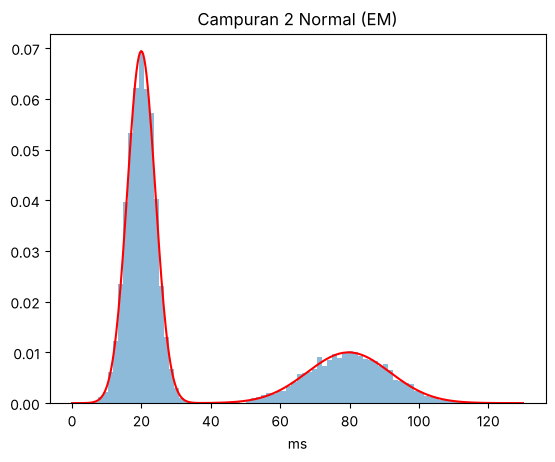

In [7]:
X=np.r_[rng.normal(20,4,7000),rng.normal(80,12,3000)].reshape(-1,1)
bic={k:GaussianMixture(k,random_state=0,n_init=3).fit(X).bic(X) for k in range(1,6)}
print("BIC:",{k:round(v) for k,v in bic.items()},"-> terbaik k =",min(bic,key=bic.get))
gm=GaussianMixture(2,random_state=0,n_init=3).fit(X); o=np.argsort(gm.means_.ravel())
print("bobot :",gm.weights_[o].round(3),"(0.7,0.3)")
print("mean  :",gm.means_.ravel()[o].round(2),"(20,80)")
print("sd    :",np.sqrt(gm.covariances_.ravel()[o]).round(2),"(4,12)")
print("P(miss | 45ms) =",gm.predict_proba([[45]])[0][o][1].round(4))
xs=np.linspace(0,130,400).reshape(-1,1)
plt.hist(X,bins=80,density=True,alpha=.5); plt.plot(xs,np.exp(gm.score_samples(xs)),'r'); plt.xlabel("ms"); plt.title("Campuran 2 Normal (EM)"); plt.show()

**Interpretasi:** BIC terendah pada k=2 → data memang bimodal. EM memulihkan bobot, mean, dan sd dengan sangat dekat. `predict_proba` memberi **posterior komponen** (soft clustering): latensi 45 ms hampir pasti berasal dari kelompok mana yang dekat, dan tidak ada tebakan keras.

### Soal 3.3 — `KernelDensity`: PDF nonparametrik dan pengaruh bandwidth
Estimasi PDF dari 300 sampel campuran; bandingkan bandwidth kecil, sedang, besar terhadap PDF sebenarnya (ukur dengan *integrated squared error*).

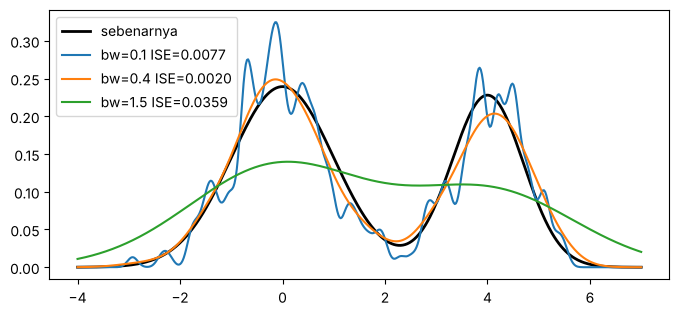

Luas di bawah KDE (bw=.4): 1.0


In [8]:
s=np.r_[rng.normal(0,1,180),rng.normal(4,.7,120)].reshape(-1,1)
xs=np.linspace(-4,7,500).reshape(-1,1)
true=.6*stats.norm(0,1).pdf(xs.ravel())+.4*stats.norm(4,.7).pdf(xs.ravel())
fig,ax=plt.subplots(figsize=(8,3.5)); ax.plot(xs,true,'k',lw=2,label="sebenarnya")
for bw in (.1,.4,1.5):
    kde=KernelDensity(kernel="gaussian",bandwidth=bw).fit(s); d=np.exp(kde.score_samples(xs))
    ise=np.trapezoid((d-true)**2,xs.ravel()); ax.plot(xs,d,label=f"bw={bw} ISE={ise:.4f}")
ax.legend(); plt.show()
print("Luas di bawah KDE (bw=.4):",np.trapezoid(np.exp(KernelDensity(bandwidth=.4).fit(s).score_samples(xs)),xs.ravel()).round(4))

**Interpretasi:** Bandwidth kecil → kurva bergerigi (*overfit*), terlalu besar → kedua puncak menyatu (*oversmooth*); bw≈0,4 paling dekat (ISE terendah). Memilih bandwidth adalah *bias–variance trade-off*. Luas total tetap ≈1 (syarat PDF).

### Soal 3.4 — `BernoulliNB` & distribusi Bernoulli fitur: deteksi malware dari izin aplikasi
Setiap aplikasi punya 5 izin biner. Peluang izin berbeda antara malware dan aplikasi normal; latih BernoulliNB dan baca parameter Bernoulli yang dipelajari.

In [9]:
perm=["internet","sms","kontak","kamera","root"]
pm=np.array([.9,.7,.6,.3,.5]); pb=np.array([.8,.1,.3,.3,.02])
n=6000; ym=(rng.random(n)<.2).astype(int)
Xb=(rng.random((n,5))<np.where(ym[:,None]==1,pm,pb)).astype(int)
b=BernoulliNB().fit(Xb,ym)
print(pd.DataFrame({"izin":perm,"P(izin|malware) belajar":np.exp(b.feature_log_prob_[1]).round(3),"teori":pm,"P(izin|normal) belajar":np.exp(b.feature_log_prob_[0]).round(3),"teori ":pb}).to_string(index=False))
app=np.array([[1,1,0,0,1]]); print("\nP(malware | internet+sms+root) =",b.predict_proba(app)[0,1].round(4))
print("CV akurasi:",cross_val_score(BernoulliNB(),Xb,ym,cv=5).mean().round(4),"| baseline mayoritas:",(1-ym.mean()).round(3))

    izin  P(izin|malware) belajar  teori  P(izin|normal) belajar  teori 
internet                    0.901    0.9                   0.807    0.80
     sms                    0.713    0.7                   0.102    0.10
  kontak                    0.580    0.6                   0.294    0.30
  kamera                    0.291    0.3                   0.291    0.30
    root                    0.516    0.5                   0.020    0.02

P(malware | internet+sms+root) = 0.9677
CV akurasi: 0.9093 | baseline mayoritas: 0.801


**Interpretasi:** Parameter Bernoulli yang dipelajari ≈ parameter sebenarnya (selisih ≤0,02). Izin `root` dan `sms` paling diskriminatif (rasio peluang besar). Aplikasi dengan kombinasi internet+sms+root hampir pasti malware; akurasi validasi silang melampaui baseline mayoritas 0,8.

## 4. Pengembangan Contoh Permasalahan
### Soal 4.1 — Pergeseran prior (*prior shift*): sesuaikan `priors` di produksi
Model dilatih pada data seimbang (prior 50/50) tetapi kenyataannya serangan hanya 2%. Bandingkan presisi bila `priors` diperbaiki lewat Bayes.

In [10]:
def gen(n,prev,seed):
    r=np.random.default_rng(seed); yy=(r.random(n)<prev).astype(int)
    return np.where(yy[:,None]==1,r.normal(1.5,1,(n,2)),r.normal(0,1,(n,2))),yy
Xtr,ytr=gen(20000,.5,0); Xte,yte=gen(200000,.02,1)
for nm,pri in [("prior=0.5 (salah)",[.5,.5]),("prior=0.02 (benar)",[.98,.02])]:
    m=GaussianNB(priors=pri).fit(Xtr,ytr); pr=m.predict(Xte)
    tn,fp,fn,tp=confusion_matrix(yte,pr).ravel()
    print(f"{nm:20} alarm={tp+fp:>6}  presisi={tp/(tp+fp):.3f}  recall={tp/(tp+fn):.3f}  FP={fp}")

prior=0.5 (salah)    alarm= 31767  presisi=0.108  recall=0.848  FP=28343


prior=0.02 (benar)   alarm=  1269  presisi=0.699  recall=0.220  FP=382


**Interpretasi:** Dengan prior salah (0,5) model terlalu agresif: banyak *false positive* dan presisi rendah. Dengan prior benar (0,02) FP turun drastis dan presisi naik, dengan mengorbankan recall. Prior adalah bagian dari model — harus disesuaikan dengan populasi penerapan.

### Soal 4.2 — Deteksi anomali login dengan density estimation
Latih KDE pada login normal (jam & jumlah gagal), tetapkan ambang pada persentil ke-1 log-likelihood, dan evaluasi pada 3 kasus: normal, tengah malam banyak gagal, jam kerja sedikit gagal.

In [11]:
jam=np.clip(rng.normal(13,3,5000),0,24); gagal=rng.poisson(.5,5000)
Xn=np.c_[jam,gagal]; kde=KernelDensity(bandwidth=.8).fit(Xn)
thr=np.percentile(kde.score_samples(Xn),1)
cases={"normal (13h,0 gagal)":[13,0],"jam 3 pagi, 6 gagal":[3,6],"jam 14, 1 gagal":[14,1],"jam 13, 8 gagal":[13,8]}
for k,v in cases.items():
    ll=kde.score_samples([v])[0]; print(f"{k:24} logL={ll:8.2f}  anomali={ll<thr}")
print("ambang (persentil 1) =",round(thr,2),"| FPR pada data normal =",(kde.score_samples(Xn)<thr).mean())

normal (13h,0 gagal)     logL=   -3.04  anomali=False
jam 3 pagi, 6 gagal      logL=  -19.77  anomali=True
jam 14, 1 gagal          logL=   -3.26  anomali=False
jam 13, 8 gagal          logL=  -21.71  anomali=True


ambang (persentil 1) = -6.57 | FPR pada data normal = 0.01


**Interpretasi:** Titik di daerah padat peluang (jam kerja, 0–1 gagal) punya log-likelihood tinggi, sedangkan kombinasi tidak lazim punya likelihood sangat rendah → ditandai anomali. Persentil ke-1 mengatur FPR ≈1% pada data normal — pilihan ambang adalah trade-off biaya false alarm vs kebocoran.

### Soal 4.3 — Validasi silang & selang kepercayaan akurasi (Iris)
Evaluasi `GaussianNB` dengan 10-fold CV, hitung CI akurasi (t-distribution) dan bandingkan dengan bootstrap.

In [12]:
from sklearn.utils import resample
iris=load_iris(); Xi,yi=iris.data,iris.target
sc=cross_val_score(GaussianNB(),Xi,yi,cv=10)
m,se=sc.mean(),stats.sem(sc); lo,hi=stats.t.interval(.95,9,loc=m,scale=se)
print("akurasi CV:",sc.round(2),"\nmean=%.3f  CI95(t)=[%.3f, %.3f]"%(m,lo,hi))
bs=[resample(sc,random_state=i).mean() for i in range(3000)]; print("CI bootstrap =",np.percentile(bs,[2.5,97.5]).round(3))
g=GaussianNB().fit(Xi,yi); print("P(kelas | sampel pertama):",{str(k):float(v) for k,v in zip(iris.target_names,g.predict_proba(Xi[:1])[0].round(4))})

akurasi CV: [0.93 0.93 1.   0.93 0.93 0.93 0.87 1.   1.   1.  ] 
mean=0.953  CI95(t)=[0.921, 0.986]


CI bootstrap = [0.927 0.98 ]
P(kelas | sampel pertama): {'setosa': 1.0, 'versicolor': 0.0, 'virginica': 0.0}


**Interpretasi:** Akurasi ≈0,95 dengan CI sempit, dan CI bootstrap sebanding dengan CI-t. Estimasi akurasi memiliki ketidakpastian (varian antar-fold) sehingga perbandingan model sebaiknya disertai selang kepercayaan. Posterior sampel pertama hampir 100% setosa.

## Kesimpulan
1. Naive Bayes = Teorema Bayes + asumsi independensi; hasil manual identik dengan `predict_proba`.
2. Presisi (PPV) adalah probabilitas posterior yang bergantung pada prevalensi; prior yang salah merusak kinerja produksi.
3. `GaussianMixture` dan `KernelDensity` mengestimasi distribusi dari data (parametrik vs nonparametrik); BIC dan bandwidth mengatur kompleksitas.
4. Probabilitas model harus dievaluasi (log-loss, Brier, kalibrasi) — bukan hanya akurasi.